In [1]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from tensorflow import keras
from tensorflow.keras import layers

In [2]:
digits = load_digits()

images = digits.images
labels = digits.target

print("Number of images:", images.shape)
print("Each image is:", images.shape[1], "x", images.shape[2], "pixels")
print("Example labels:", labels[:10])

Number of images: (1797, 8, 8)
Each image is: 8 x 8 pixels
Example labels: [0 1 2 3 4 5 6 7 8 9]


In [3]:
images

array([[[ 0.,  0.,  5., ...,  1.,  0.,  0.],
        [ 0.,  0., 13., ..., 15.,  5.,  0.],
        [ 0.,  3., 15., ..., 11.,  8.,  0.],
        ...,
        [ 0.,  4., 11., ..., 12.,  7.,  0.],
        [ 0.,  2., 14., ..., 12.,  0.,  0.],
        [ 0.,  0.,  6., ...,  0.,  0.,  0.]],

       [[ 0.,  0.,  0., ...,  5.,  0.,  0.],
        [ 0.,  0.,  0., ...,  9.,  0.,  0.],
        [ 0.,  0.,  3., ...,  6.,  0.,  0.],
        ...,
        [ 0.,  0.,  1., ...,  6.,  0.,  0.],
        [ 0.,  0.,  1., ...,  6.,  0.,  0.],
        [ 0.,  0.,  0., ..., 10.,  0.,  0.]],

       [[ 0.,  0.,  0., ..., 12.,  0.,  0.],
        [ 0.,  0.,  3., ..., 14.,  0.,  0.],
        [ 0.,  0.,  8., ..., 16.,  0.,  0.],
        ...,
        [ 0.,  9., 16., ...,  0.,  0.,  0.],
        [ 0.,  3., 13., ..., 11.,  5.,  0.],
        [ 0.,  0.,  0., ..., 16.,  9.,  0.]],

       ...,

       [[ 0.,  0.,  1., ...,  1.,  0.,  0.],
        [ 0.,  0., 13., ...,  2.,  1.,  0.],
        [ 0.,  0., 16., ..., 16.,  5.,  0.

In [4]:
# fig, axes = plt.subplots(1, 8, figsize=(10, 2))
# for i, v in enumerate(axes):
#      v.imshow(images[i])

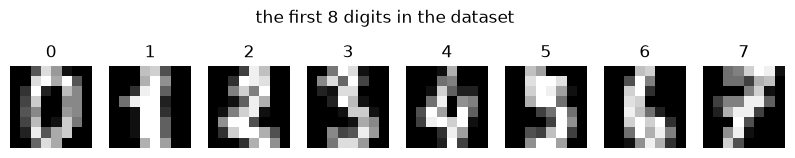

In [5]:
fig, axes = plt.subplots(1, 8, figsize=(10, 2))
for i, ax in enumerate(axes):
    ax.imshow(images[i], cmap="gray")
    ax.set_title(str(labels[i]))
    ax.axis("off")
plt.suptitle("the first 8 digits in the dataset")
plt.show()

In [6]:
x = images.reshape(-1, 8, 8, 1).astype("float32")

x = x/16.0
y = labels

print("x shape:", x.shape)
print("Smallest pixel value:", x.min(), "\nLargest pixel value:", x.max())


x shape: (1797, 8, 8, 1)
Smallest pixel value: 0.0 
Largest pixel value: 1.0


In [7]:
x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, random_state=42 
)

print("Training Images:", x_train.shape[0])
print("Test Images:", x_test.shape[0]) 

Training Images: 1437
Test Images: 360


In [8]:
model = keras.Sequential([
    keras.Input(shape=(8, 8, 1)),

    layers.Conv2D(8, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(16, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),
    layers.Dense(32, activation="relu"),
    layers.Dense(10, activation="softmax"),
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 8, 8, 8)        │            80 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 4, 4, 8)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 4, 4, 16)       │         1,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 2, 2, 16)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           330 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,658 (14.29 KB)

 Trainable params: 3,658 (14.29 KB)

 Non-trainable params: 0 (0.00 B)

In [10]:
model.compile(
    optimizer= 'adam',
    loss= 'sparse_categorical_crossentropy',
    metrics= ['accuracy'],
)

history = model.fit(
    x_train, y_train,
    validation_split = 0.2,
    batch_size = 32,
    epochs = 15,
    verbose = 1,
)

Epoch 1/15
36/36 ━━━━━━━━━━━━━━━━━━━━ 3s 16ms/step - accuracy: 0.9547 - loss: 0.1754 - val_accuracy: 0.9132 - val_loss: 0.2312
Epoch 2/15
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9556 - loss: 0.1650 - val_accuracy: 0.9444 - val_loss: 0.2099
Epoch 3/15
36/36 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.9582 - loss: 0.1527 - val_accuracy: 0.9444 - val_loss: 0.1790
Epoch 4/15
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9539 - loss: 0.1451 - val_accuracy: 0.9410 - val_loss: 0.1767
Epoch 5/15
36/36 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.9643 - loss: 0.1358 - val_accuracy: 0.9514 - val_loss: 0.1698
Epoch 6/15
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9687 - loss: 0.1257 - val_accuracy: 0.9375 - val_loss: 0.1640
Epoch 7/15
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9704 - loss: 0.1170 - val_accuracy: 0.9514 - val_loss: 0.1528
Epoch 8/15
36/36 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.9626 - loss: 0.1117 - val_accuracy: 0.9514 - val_los